# WDSD: revisión de literatura, modelos base y línea base estadística

**Autores:** Ivan Berrio, Jose David Castillo y Jaime Besada.

Segunda parte del Entregable 1. La primera es el EDA orientado a instancias (`02_eda_instancias.ipynb`). Este notebook contiene:

- **Sección 3.** Revisión de literatura (PRISMA 2020, tabla de síntesis y selección de los tres modelos base).
- **Sección 4.** Implementación de los modelos base: Mask R-CNN, YOLOv8-seg y SOLOv2, con 5 semillas cada uno.
- **Sección 5.** Línea base estadística sobre las 15 corridas.

Las celdas de código no entrenan nada: leen los resultados guardados en `results/instancias/corridas/`. El entrenamiento se reproduce con `entrenar_instancias.py` y `solov2_instancias.py` (instrucciones en `ENTRENAMIENTO_INSTANCIAS.md`).

## 0. Configuración

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image, Markdown
import estadistica_instancias as EI

LIT = ROOT / 'literatura' / 'instancias'
CORR = ROOT / 'results' / 'instancias' / 'corridas'
MODELOS = {'maskrcnn': 'Mask R-CNN', 'yolov8seg': 'YOLOv8-seg', 'solov2': 'SOLOv2'}
pd.set_option('display.max_colwidth', 90)
print('Corridas encontradas:', sorted(p.name for p in CORR.glob('*_s*') if (p / 'metricas.json').exists()))

Corridas encontradas: ['maskrcnn_s42', 'maskrcnn_s43', 'maskrcnn_s44', 'maskrcnn_s45', 'maskrcnn_s46', 'solov2_s42', 'solov2_s43', 'solov2_s44', 'solov2_s45', 'solov2_s46', 'yolov8seg_s42', 'yolov8seg_s43', 'yolov8seg_s44', 'yolov8seg_s45', 'yolov8seg_s46']


## 3. Revisión de literatura

### 3.1 Protocolo de búsqueda (PRISMA 2020)

- **Bases:** Web of Science (`TS=`), Scopus (`TITLE-ABS-KEY`) e IEEE Xplore ("All Metadata").
- **Fecha:** 2026-11-07. **Años:** 2018–2026.
- **Cadena C4 (Scopus):**

  ```
  TITLE-ABS-KEY("instance segmentation") AND TITLE-ABS-KEY(screw* OR bolt* OR fastener* OR disassembl* OR "e-waste" OR weee OR remanufactur* OR "industrial part*" OR "small object*") AND TITLE-ABS-KEY("deep learning" OR CNN OR "neural network*") AND TITLE-ABS-KEY(compar* OR baseline*) AND PUBYEAR > 2017
  ```

  En WoS se usa la misma cadena con `TS=` y `PY=(2018-2026)`.
- **Inclusión:**
  - segmentación de instancias con aprendizaje profundo;
  - dominio de tornillos, sujetadores, desmontaje o remanufactura;
  - compara al menos dos modelos de segmentación de instancias.
- **Exclusión:**
  - solo detección por cajas;
  - un solo modelo, sin comparación;
  - sin texto completo.
- **Otras fuentes:**
  - el artículo original del dataset (Kalitsios et al., 2022);
  - el único trabajo posterior que usa WDSD (Chao et al., 2025).
- **Proceso:**
  - Duplicados por DOI o, sin DOI, por título normalizado.
  - Primer cribado de título y resumen con un filtro de términos del dominio, registrado en `cribado_instancias_C4.csv`.
  - Revisión manual de los 17 registros del dominio y lectura de texto completo por el equipo.

| Etapa | n |
|---|---|
| Identificados (WoS 43, Scopus 62, IEEE 166) | 271 |
| Duplicados eliminados | 52 |
| Cribados por título y resumen | 219 |
| Excluidos por no tratar el dominio | 202 |
| Registros del dominio | 17 |
| Excluidos por resumen (fuera de dominio) | 2 |
| Buscados en texto completo | 15 |
| No recuperados (sin acceso al texto completo) | 4 |
| Evaluados en texto completo | 11 |
| Excluidos por usar un solo modelo | 4 |
| Incluidos de la búsqueda | 7 |
| Incluidos de otras fuentes | 2 |
| **Incluidos en la síntesis** | **9** |

Excluidos por resumen, por estar fuera de dominio: vértebras en rayos X (10.1007/s10278-026-02343-x) y huellas de edificios (10.12082/dqxxkx.2025.240628).

No recuperados:
- Bolt Sorting (10.1109/case59546.2024.10711806);
- grietas en remaches de tren (10.1038/s41598-024-61396-6);
- componentes de vía férrea (10.13382/j.jemi.b2407985);
- estado de sujetadores de vía con Mask R-CNN mejorada (10.3969/j.issn.1001-4632.2022.01.06).



**Figura 3.1.** Diagrama PRISMA 2020 de la búsqueda (generado con `literatura/instancias/prisma_instancias.py`).

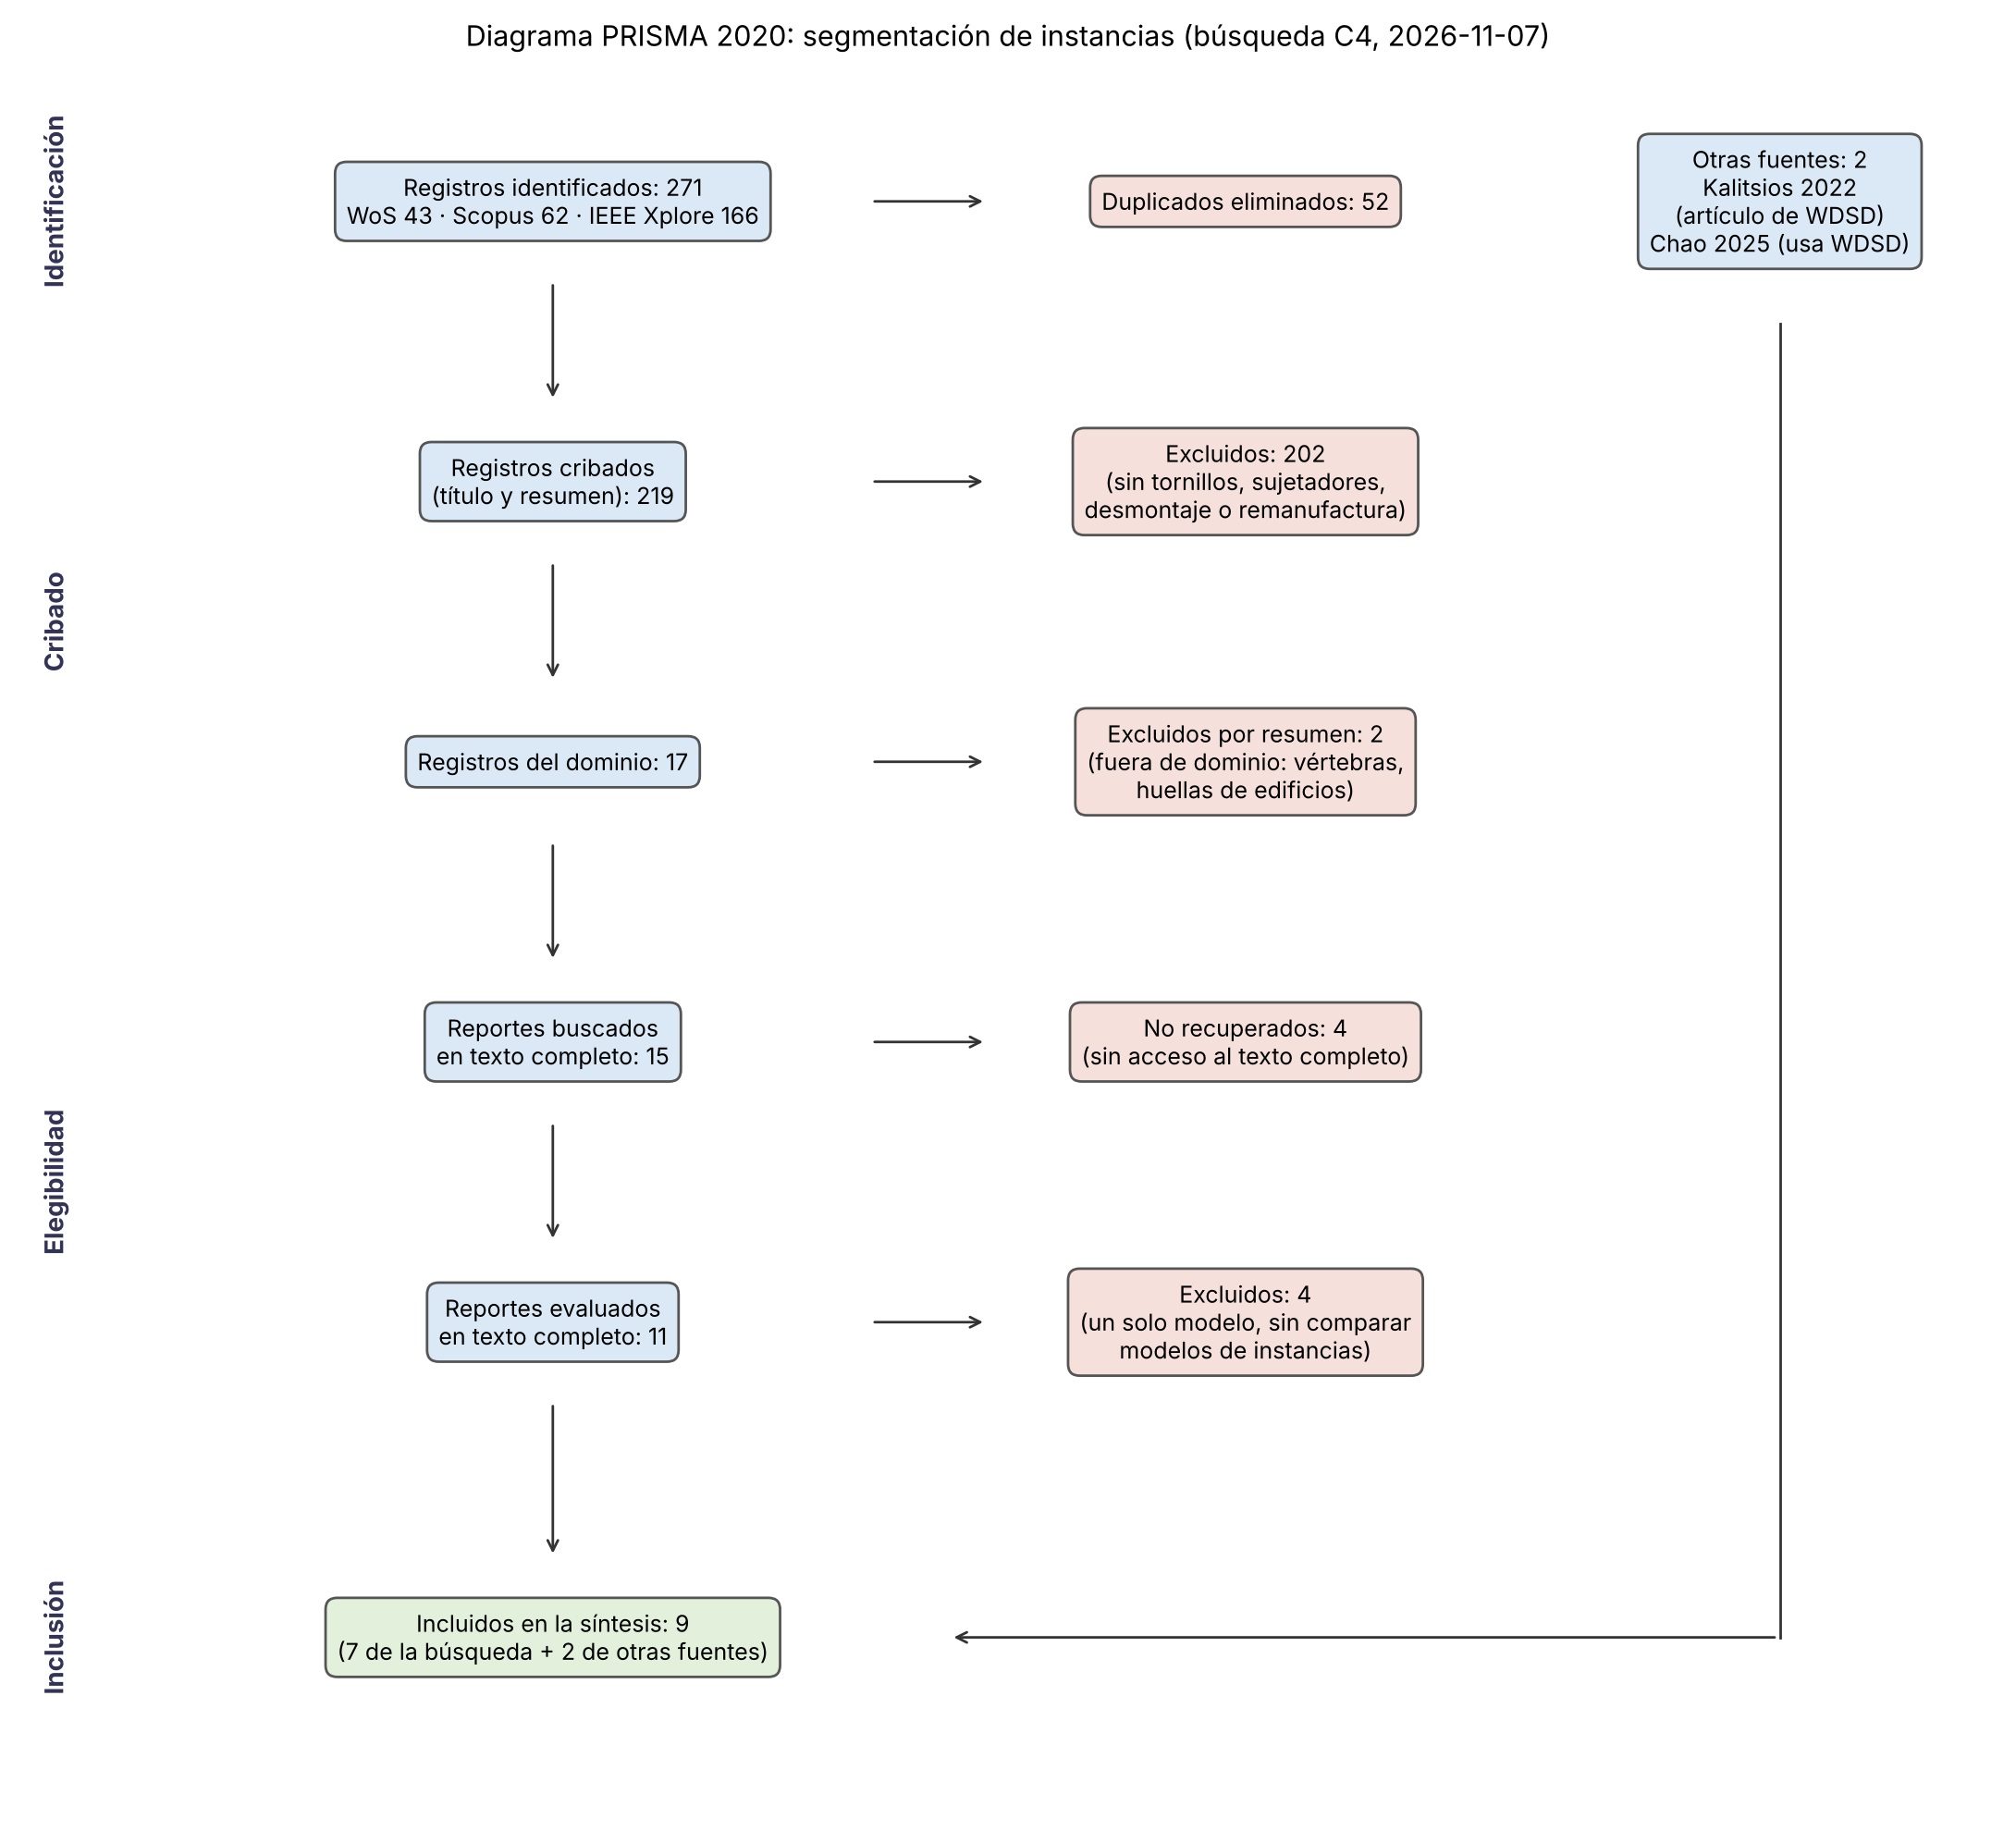

In [2]:
Image(filename=str(LIT / 'prisma_instancias.png'), width=700)

### 3.2 Selección de los modelos base y tabla de síntesis

**Criterios:**
1. Frecuencia como comparador en la literatura.
2. Complejidad distinta entre sí.
3. No redundancia: cada modelo obtiene las instancias de una forma distinta.
4. Viables en una GPU de 6 GB.

**Frecuencia:**

| Modelo | Resúmenes de la búsqueda (219) | Estudios de la síntesis (9) |
|---|---|---|
| YOLO (cualquier versión) | 64 | — |
| Mask R-CNN | 59 | 6 |
| YOLO-seg | 25 | 5 |
| SOLO / SOLOv2 | 10 | 2 |
| YOLACT | 7 | 3 |

**Terna elegida: Mask R-CNN, YOLOv8-seg y SOLOv2.** Cubre las tres familias:

| Modelo | Familia |
|---|---|
| Mask R-CNN | Dos etapas con cajas |
| YOLOv8-seg | Una etapa con cajas y prototipos |
| SOLOv2 | Una etapa sin cajas |

**Limitación declarada.** En texto completo YOLACT supera a SOLOv2 (3 estudios contra 2), pero en los resúmenes el orden se invierte (7 contra 10). Además, YOLACT comparte con YOLOv8-seg el mecanismo de prototipos, así que sería redundante.

**Equivalencia con la regresión logística.** Las tres cabezas de máscara terminan en una sigmoide por píxel sobre características aprendidas, es decir, en una regresión logística por píxel:
- Mask R-CNN y YOLOv8-seg la entrenan con entropía cruzada binaria, que es la verosimilitud de la regresión logística.
- SOLOv2 la entrena con pérdida Dice.

Por eso son la "línea base mínima razonable" del enunciado para este tipo de problema.

**Tabla 3.4.** Tabla de síntesis de los 9 estudios incluidos.

In [3]:
tabla = pd.read_csv(LIT / 'tabla_sintesis_instancias.csv')
display(tabla[['id', 'referencia', 'problema', 'dataset', 'modelos_DL_de_referencia', 'metricas',
               'valores_modelos_base', 'particion', 'repeticiones', 'prueba_estadistica']])

,id,referencia,problema,dataset,modelos_DL_de_referencia,metricas,valores_modelos_base,particion,repeticiones,prueba_estadistica
0,I1,Chen W.-Y. et al. (2022). Real-Time Instance Segmentation of Metal Screw Defects Based...,Segmentación de instancias de defectos en cabezas de tornillo,Propio: 3200 imgs microscopio (2880 train / 320 val),YOLACT vs Mask R-CNN,AP caja y máscara (IoU 0.5–0.95),"YOLACT mAP máscara 41.37, caja 40.11; Mask R-CNN solo comparado por curvas de entrenam...",Aleatoria 90/10 tras aumentar datos (posible fuga),1 corrida,No
1,I2,Qi K. et al. (2022). Fastener counting method with an improved Blendmask. ASCC 2022.,Conteo de sujetadores por segmentación de instancias (densos/dispersos),"Propio: 413 imgs, 9589 instancias","Mask R-CNN, SOLO, BlendMask (+ propuesta)","Error de cantidad, distancia media al centro de gravedad",Denso error 0.3/0.5: Mask R-CNN 8.84/10.40 %; SOLO 2.21/7.54 %; BlendMask 1.95/5.46 %....,"Fija train/val (366/47), sin test",1 corrida,No
2,I3,Ma J. et al. (2023). LPHD: Line Perspective Hexagonal Screw Detection. CCC 2023.,Contorno de tornillos hexagonales para atornillado robótico,Propio: 1115 imgs (1015 train / 100 test),Mask R-CNN (control) vs YOLOv5 + geometría (LPHD),"IoU medio, recall, tiempo","Mask R-CNN IoU 92.9 %, recall 98 %, 0.141 s; LPHD IoU 91.4 %, recall 100 %, 0.057 s",Fija 1015/100,1 corrida,No
3,I4,Wang Y. et al. (2024). YOLOv8n-BAseg Instance Segmentation Network for Angle Tower Bol...,Segmentación de instancias de grupos de pernos y placas en torres,Propio: 1050 imgs (aumentadas desde 210 por clase),"YOLOv8n-seg, YOLOv8s-seg, Fast-SAM (+ propuesta)","mAP50, parámetros, ms/img",YOLOv8n-seg 94.9 % (3.26 M); YOLOv8s-seg 99.3 % (11.78 M); Fast-SAM sin mAP,7:1:2 tras aumentar datos (posible fuga),1 corrida,"No (dice ""significantly"")"
4,I5,AF-YOLO (2026). A High-Precision Aircraft Safety Wire Segmentation Network for Assembl...,Segmentación de instancias de alambres/fusibles de seguridad en ensamble aeronáutico (...,Propio,"Mask R-CNN, YOLACT, SOLOv2, YOLOv8-seg, BlendMask (+ propuesta)","mAP, AP50, AP75, AR",mAP: Mask R-CNN 83.2; YOLACT 84.7; SOLOv2 86.1; YOLOv8-seg 87.3; BlendMask 89.6,Aleatoria 7:2:1,1 corrida,"No (dice ""significantly"")"
5,I6,Engineering Applications of AI 133 (2024) 108318. Instance segmentation algorithm for ...,Segmentación de instancias de piezas desmontadas de vehículos fuera de uso,Propio: 385 imgs originales → 4235 aumentadas,"Mask R-CNN, YOLACT, YOLOv5s-seg (+ SPGNet)","mAP@0.5 y 0.5:0.95 caja/máscara, GFLOPs, ms",mAP@0.5 máscara: Mask R-CNN 78.3; YOLACT 90.5; YOLOv5s-seg 90.1,7:3 train/val,1 corrida,No
6,I7,Footwear Damage Assessment for Remanufacturing: A Multi-View RGB Dataset and Instance ...,Segmentación de instancias de daños en calzado para remanufactura,Propio: 3858 imgs multivista,"YOLOv8s-seg, YOLOv11n-seg, Roboflow 3.0, RF-DETR","mAP@50, P, R, F1",mAP@50 global: YOLOv8s-seg 0.284; YOLOv11n-seg 0.308; Roboflow3 0.345; RF-DETR 0.339,80/10/10 agrupada por zapato (sin fuga),1 corrida,No
7,WDSD-1,Kalitsios G. et al. (2022). Vision-Enhanced System for Human-Robot Disassembly Factory...,Segmentación de instancias de tornillos en desmontaje de RAEE,WDSD (nuestro dataset),Mask R-CNN,AP COCO,Ver tabla anterior (sintesis/tabla_sintesis.csv),Oficial 765/90/90 (fuga por casi-duplicados),1 corrida,No
8,WDSD-2,Chao et al. (2025). Digital Twin.,Segmentación de instancias de tornillos y agujeros,387 imgs WDSD + propias,YOLOv8-seg (variante SM-Seg),mAP,Ver tabla anterior,Aleatoria tras aumentar datos,1 corrida,No


### 3.3 Modelos base

| Modelo | Artículo original | DOI o referencia |
|---|---|---|
| Mask R-CNN | He, Gkioxari, Dollár y Girshick (2017), ICCV, pp. 2980–2988 | 10.1109/ICCV.2017.322. Versión TPAMI 42(2):386–397, 2020: 10.1109/TPAMI.2018.2844175 |
| YOLOv8-seg | Jocher, Chaurasia y Qiu (2023), *Ultralytics YOLOv8*, versión 8.0.0, licencia AGPL-3.0 | No tiene artículo ni DOI; se cita como software: https://github.com/ultralytics/ultralytics. Mecanismo de prototipos: YOLACT, Bolya et al. (2019), ICCV, 10.1109/ICCV.2019.00925 |
| SOLOv2 | Wang, Zhang, Kong, Li y Shen (2020), NeurIPS 33 | arXiv 2003.10152, 10.48550/arXiv.2003.10152. Las páginas del volumen no se verificaron. Base SOLO: Wang et al. (2020), ECCV, pp. 649–665, 10.1007/978-3-030-58523-5_38 |

#### Mask R-CNN: dos etapas, con cajas

1. Una red de propuestas (RPN) sugiere regiones sobre un pirámide de características (ResNet-50-FPN).
2. RoIAlign recorta las características de cada región con interpolación bilineal, sin redondear coordenadas.
3. Tres cabezas en paralelo predicen clase, caja y una máscara de $m\times m$. En torchvision, $m=28$: RoIAlign de 14×14 seguido de una convolución transpuesta ×2.

**Pérdida por región**:

$$L = L_{cls} + L_{box} + L_{mask}, \qquad L_{mask} = -\frac{1}{m^2}\sum_{i,j}\big[y_{ij}\log\sigma(z_{ij}) + (1-y_{ij})\log(1-\sigma(z_{ij}))\big]$$

- $L_{mask}$ se calcula solo sobre el canal de la clase verdadera.
- torchvision suma además las dos pérdidas de la RPN (objetividad y regresión de la caja).

#### YOLOv8-seg: una etapa, con cajas y prototipos

En una sola pasada, la cabeza predice para cada posición:
- la caja;
- la clase;
- $k=32$ coeficientes de máscara.

En paralelo, una rama *Proto* genera 32 máscaras prototipo $P_k$ a 1/4 de la resolución de entrada. Toma P3 (paso 8) y lo sobremuestrea ×2.

**Máscara de una detección:**

$$\hat m = \sigma\Big(\sum_{k=1}^{32} c_k P_k\Big)$$

recortada a su caja.

**Pérdida**:

$$L = 7.5\,L_{CIoU} + 7.5\,L_{seg} + 0.5\,L_{cls} + 1.5\,L_{DFL}$$

- $L_{seg}$ es entropía cruzada binaria por píxel, recortada a la caja y normalizada por su área.
- $L_{cls}$ es entropía cruzada binaria.
- $L_{DFL}$ es la *distribution focal loss* de la caja.

#### SOLOv2: una etapa, sin cajas

1. La imagen se divide en una rejilla de $S\times S$ por nivel de la pirámide ($S$ = 40, 36, 24, 16, 12).
2. La celda que contiene el centro de un objeto es la responsable de ese objeto.
3. La rama de categoría predice un mapa $S\times S\times C$.
4. La rama de *kernel* predice, para cada celda, un filtro $G_{ij}$.
5. La máscara sale de una convolución dinámica, $M_{ij} = G_{ij} * F$, donde $F$ es una característica de máscara unificada a 1/4 de escala.
6. Las máscaras duplicadas se suprimen con Matrix NMS, que decae los scores en forma matricial con $f(\mathrm{iou}) = \exp(-\mathrm{iou}^2/\sigma)$.

**Pérdida**:

$$L = L_{cate} + \lambda L_{mask},\quad \lambda = 3,\qquad L_{mask} = \frac{1}{N_{pos}}\sum_k \mathbb{1}\{p^*_{k} > 0\}\,\big(1 - D(p_k, q_k)\big),\qquad D(p,q) = \frac{2\sum p_{xy}q_{xy}}{\sum p_{xy}^2 + \sum q_{xy}^2}$$

$L_{cate}$ es una *focal loss* con $\gamma = 2$ y $\alpha = 0.25$.

#### Parámetros y costo

Conteo hecho con el código del proyecto, con 1 clase:

| Modelo | Parámetros | Referencia publicada |
|---|---|---|
| Mask R-CNN R50-FPN (torchvision 0.29) | 43 922 395 | Con 91 clases da 44 401 393, igual a la documentación de torchvision (134.4 GFLOPs a 800 px) |
| YOLOv8n-seg (ultralytics 8.4.207) | 3 263 811 | 11.3 GFLOPs a 640 px, fusionado |
| SOLOv2 R50-FPN (MMDetection 3.3) | 46 228 801 | Comparte con Mask R-CNN el mismo ResNet-50-FPN (26.8 M parámetros) |

**Complejidad**. Para una imagen de $H\times W$:
- Cada convolución $k\times k$ de $C_{in}$ a $C_{out}$ cuesta $O(HW\,k^2C_{in}C_{out})$ en su resolución. Con la pirámide, el costo del extractor es $O(HW)$, con constantes distintas por modelo.
- **Mask R-CNN** suma un término por región: $O(HW + R\,m^2)$, con $R$ propuestas (512 por imagen en entrenamiento, hasta 1000 en inferencia).
- **YOLOv8-seg**: $O(HW + N\,k\,\tfrac{HW}{16})$ para ensamblar $N$ máscaras desde $k=32$ prototipos.
- **SOLOv2**: $O(HW + N\,E\,\tfrac{HW}{16})$ para la convolución dinámica de $N$ candidatos, más $O(N^2)$ en Matrix NMS.
- Las tres son lineales en el número de píxeles. Difieren en la constante y en cómo crecen con el número de instancias. El tiempo medido por corrida está en la sección 4.

### 3.4 Comparación crítica y vacío

Lectura completa en `lectura_critica_instancias.md`. Resumen:

- **No hay un orden estable entre los modelos.** En el único estudio con los tres modelos (AF-YOLO, objetos menores al 1 % de la imagen), el mAP de máscara queda en 83.2 (Mask R-CNN), 86.1 (SOLOv2) y 87.3 (YOLOv8-seg). En otro dominio, Mask R-CNN queda 12 puntos por debajo de los modelos de una etapa (SPGNet), y en conteo de sujetadores el orden cambia según la métrica.
- **Calidad metodológica de los 9 estudios:**
  - 0 usan más de una corrida;
  - 0 hacen prueba estadística;
  - 1 usa partición agrupada;
  - 3 aumentan datos antes de partir.
- **Los dos trabajos sobre WDSD:**
  - Kalitsios 2022: solo Mask R-CNN, partición oficial con fuga, AP 0.586.
  - Chao 2025: YOLOv8-seg, partición aleatoria tras aumentar datos.
- **Vacío:** ningún estudio compara Mask R-CNN, YOLOv8-seg y SOLOv2 en segmentación de instancias de tornillos con partición agrupada, varias semillas e inferencia estadística. Este trabajo cubre ese vacío.

## 4. Implementación de los modelos base

### 4.1 Protocolo experimental

Se entrenaron los tres modelos base (Mask R-CNN, YOLOv8-seg y SOLOv2) con cinco semillas cada uno (42 a 46): 15 corridas en total. Todas las corridas comparten el mismo protocolo:

- **Partición.** La partición agrupada congelada del EDA (`results/eda/particion.csv`): 744 imágenes de entrenamiento, 93 de validación y 108 de prueba. En prueba hay 14 grupos (sesiones o escenas de captura). Ninguna sesión aparece en más de un conjunto.
- **Entrada.** Imagen completa de 1280×720, sin reescalar ni recortar, porque el diámetro mediano de un tornillo es de 11.7 px (ver el EDA). El único aumento de datos es el volteo horizontal.
- **Inicialización.** Pesos preentrenados en COCO para los tres modelos.
- **Selección del modelo.** Se guarda la mejor época según el conjunto de validación: AP de máscara en Mask R-CNN y SOLOv2, y el *fitness* de ultralytics en YOLOv8-seg. El conjunto de prueba se evalúa una sola vez por corrida.
- **Umbral de confianza.** Las métricas por instancia (F1 y PQ) necesitan un umbral sobre el puntaje de cada detección. Se elige en validación, como el que maximiza el F1 medio por imagen, y se aplica sin cambios en prueba. El AP no usa umbral.

Tabla 4.1. Configuración por modelo.

| Modelo | Tipo | Parámetros | Épocas | Lote | Optimizador | Marco |
|---|---|---|---|---|---|---|
| Mask R-CNN (ResNet-50-FPN) | Dos etapas, con cajas | 43 922 395 | 12 | 2 | SGD, momento 0.9, calentamiento + coseno, lr 0.0025 × lote | torchvision 0.26 |
| YOLOv8n-seg | Una etapa, con cajas | 3 263 811 | 40 | 4 | Valores por defecto de ultralytics | ultralytics 8.4.207 |
| SOLOv2 (ResNet-50-FPN) | Una etapa, sin cajas | 46 228 801 | 12 | 2 | SGD, lr 0.01 × lote/16 (receta oficial `solov2_r50_fpn_1x_coco`) | MMDetection 3.3 |

Mask R-CNN usa anclas de 8 a 128 px en lugar de las de 32 a 512 px que trae torchvision por defecto, porque el 97 % de las cajas mide menos de 32 px (ver el EDA).

**Hardware y reparto.** Las corridas se repartieron entre dos máquinas por semilla, no por modelo:
- semillas 42, 43 y 44 en una RTX 3060 Laptop de 6 GB;
- semillas 45 y 46 en una RTX 3050 Laptop de 6 GB.

Las dos usaron la misma configuración y las mismas versiones de los paquetes (`requirements_wdsd_dl_congelado.txt`). Así, cualquier efecto de la máquina cae por igual sobre los tres modelos.

### 4.2 Corridas

Cada corrida deja en `results/instancias/corridas/<modelo>_s<semilla>/`:
- `resumen.json`: entorno, tiempo, memoria y métricas;
- `metricas.json`: AP, F1 y PQ en validación y prueba, y el umbral elegido en validación;
- `test_por_imagen.csv`: una fila por imagen de prueba (TP, FP, FN, F1, PQ), entrada de la sección 5;
- `preds_val.json` y `preds_test.json`: predicciones en formato COCO, para recalcular cualquier métrica sin reentrenar.

**Tabla 4.2.** Las 15 corridas.

In [4]:
filas = []
for d in sorted(CORR.glob('*_s*')):
    if not (d / 'resumen.json').exists():
        continue
    r = json.loads((d / 'resumen.json').read_text(encoding='utf8'))
    m = r['metricas']
    filas.append({'modelo': MODELOS[r['modelo']], 'semilla': r['semilla'], 'GPU': r['entorno']['gpu'].replace('NVIDIA GeForce ', ''),
                  'épocas': r['epocas'], 'min': round(r['s_total'] / 60, 1), 'umbral (val)': m['umbral_score'],
                  'val AP': round(m['val']['AP'], 3), 'test F1 img': round(m['test']['F1_img'], 3),
                  'test AP': round(m['test']['AP'], 3)})
corridas = pd.DataFrame(filas)
display(corridas)

,modelo,semilla,GPU,épocas,min,umbral (val),val AP,test F1 img,test AP
0,Mask R-CNN,42,RTX 3060 Laptop GPU,12,33.7,0.70,0.294,0.458,0.214
1,Mask R-CNN,43,RTX 3060 Laptop GPU,12,33.0,0.50,0.284,0.447,0.217
2,Mask R-CNN,44,RTX 3060 Laptop GPU,12,33.7,0.60,0.289,0.418,0.217
3,Mask R-CNN,45,RTX 3050 6GB Laptop GPU,12,76.0,0.60,0.282,0.450,0.214
4,Mask R-CNN,46,RTX 3050 6GB Laptop GPU,12,70.9,0.60,0.288,0.461,0.223
5,SOLOv2,42,RTX 3060 Laptop GPU,12,32.6,0.25,0.124,0.326,0.104
6,SOLOv2,43,RTX 3060 Laptop GPU,12,31.3,0.20,0.133,0.310,0.117
7,SOLOv2,44,RTX 3060 Laptop GPU,12,31.3,0.15,0.132,0.256,0.116
8,SOLOv2,45,RTX 3050 6GB Laptop GPU,12,56.3,0.20,0.132,0.305,0.111
9,SOLOv2,46,RTX 3050 6GB Laptop GPU,12,55.5,0.20,0.131,0.287,0.116


### 4.3 Costo computacional

**Tabla 4.3.** Costo computacional por corrida (entrenamiento + evaluación).

| Modelo | Minutos, RTX 3060 (3 semillas) | Minutos, RTX 3050 (2 semillas) | Memoria GPU pico (GB) |
|---|---|---|---|
| Mask R-CNN | 33.5 | 73.5 | 2.7 |
| YOLOv8-seg | 21.0 | 62.4 | 2.6 |
| SOLOv2 | 31.7 | 55.9 | ~2.6* |

\* Para SOLOv2 se toma el pico del registro de MMDetection durante el entrenamiento; el contador de PyTorch del script se reinicia dentro de MMDetection y da un valor menor que no corresponde al entrenamiento.

In [5]:
corridas.groupby(['modelo', 'GPU'])['min'].agg(['mean', 'count']).round(1)

mean  count
modelo     GPU                                 
Mask R-CNN RTX 3050 6GB Laptop GPU  73.4      2
           RTX 3060 Laptop GPU      33.5      3
SOLOv2     RTX 3050 6GB Laptop GPU  55.9      2
           RTX 3060 Laptop GPU      31.7      3
YOLOv8-seg RTX 3050 6GB Laptop GPU  62.4      2
           RTX 3060 Laptop GPU      21.0      3

## 5. Línea base estadística

### 5.1 Métricas

- **Primaria, declarada a priori: F1 de instancia por imagen.** En cada imagen se emparejan predicciones y tornillos reales con el algoritmo húngaro. Una pareja cuenta como acierto (TP) si su IoU de máscara es de al menos 0.5. Con eso, F1 = 2·TP / (2·TP + FP + FN). FP son las predicciones sin pareja y FN los tornillos sin detectar.
- **Secundarias:**
  - PQ (*panoptic quality*) = SQ × F1, donde SQ es el IoU medio de los aciertos;
  - AP50 de máscara.
- **Informativa:** AP de máscara promediado en IoU de 0.5 a 0.95, el estándar de COCO.
- **Umbral práctico:** δ = 0.03 en F1, declarado a priori en el EDA.

### 5.2 Resultados por modelo

**Tabla 5.1.** Desempeño en prueba: media, desviación estándar e intervalo de confianza del 95 % (t de Student) sobre las 5 semillas.

In [6]:
res = EI.analizar(CORR)  # imprime también el detalle; se resume abajo

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== f1 por grupo (n = 14 grupos)
 modelo  m

In [7]:
_, runs = EI.cargar(CORR)
def ic(x):
    h = stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return f'{x.mean():.3f} ± {x.std(ddof=1):.3f} [{x.mean() - h:.3f}, {x.mean() + h:.3f}]'
tabla51 = runs.groupby('modelo').agg(n=('semilla', 'nunique'), F1_img=('F1_img', ic), PQ_img=('PQ_img', ic),
                                      AP50=('AP50', ic), AP=('AP', ic)).rename(index=MODELOS)
display(tabla51)

,n,F1_img,PQ_img,AP50,AP
modelo,,,,,
Mask R-CNN,5,"0.447 ± 0.017 [0.425, 0.468]","0.313 ± 0.011 [0.300, 0.327]","0.587 ± 0.010 [0.575, 0.599]","0.217 ± 0.004 [0.212, 0.222]"
SOLOv2,5,"0.297 ± 0.027 [0.263, 0.330]","0.210 ± 0.017 [0.189, 0.231]","0.285 ± 0.017 [0.264, 0.306]","0.113 ± 0.005 [0.106, 0.119]"
YOLOv8-seg,5,"0.521 ± 0.061 [0.445, 0.597]","0.365 ± 0.040 [0.316, 0.415]","0.637 ± 0.019 [0.614, 0.661]","0.234 ± 0.008 [0.224, 0.245]"


**Tabla 5.2.** Conteos agregados en prueba (5 semillas × 108 imágenes): de dónde sale cada F1.

In [8]:
imgs, _ = EI.cargar(CORR)
cont = imgs.groupby('modelo')[['tp', 'fp', 'fn', 'n_gt', 'n_pred']].sum()
cont['precisión'] = (cont.tp / cont.n_pred).round(3)
cont['recall'] = (cont.tp / cont.n_gt).round(3)
display(cont.rename(index=MODELOS))

,tp,fp,fn,n_gt,n_pred,precisión,recall
modelo,,,,,,,
Mask R-CNN,1132,742,813,1945,1874,0.604,0.582
SOLOv2,595,410,1350,1945,1005,0.592,0.306
YOLOv8-seg,1220,706,725,1945,1926,0.633,0.627


### 5.3 Comparación estadística

**Unidad de análisis.** La unidad de independencia es el grupo, no la imagen, porque las imágenes de una misma sesión están correlacionadas. Para cada modelo y grupo de prueba se promedia el F1 de las imágenes del grupo y luego el de las semillas. Resulta una tabla de 14 grupos × 3 modelos.

**Pruebas.**
1. **Friedman** sobre los tres modelos, con los grupos como bloques. Prueba si al menos un modelo difiere de los otros.
2. **Wilcoxon pareado por grupo** para cada par de modelos, con corrección de Holm por los 3 contrastes.
3. **Intervalo bootstrap del 95 %** de la diferencia media por par, remuestreando grupos (10 000 réplicas).
4. **Efecto mínimo detectable (MDE)** de cada par, con el alfa de Holm y potencia 0.80. Si el MDE es mayor que δ, la prueba no tiene potencia para detectar una diferencia práctica, y un resultado no significativo se reporta como no concluyente, no como empate.

**Tabla 5.3.** F1 medio por grupo de prueba (promedio de las imágenes del grupo y luego de las 5 semillas).

In [9]:
g = res['por_grupo'].rename(columns=MODELOS)
n_img = imgs.drop_duplicates('archivo').groupby('grupo').size().rename('imágenes')
display(g.join(n_img).round(3))
print(f"Friedman: chi2 = {res['friedman']['estadistico']:.2f}, p = {res['friedman']['p']:.4f}")

,Mask R-CNN,SOLOv2,YOLOv8-seg,imágenes
grupo,,,,
6,0.291,0.000,0.239,15
9,0.018,0.000,0.224,28
12,0.681,0.648,0.665,15
27,0.725,0.733,0.760,13
32,0.560,0.328,0.823,16
45,0.764,0.000,0.705,1
58,0.941,0.105,0.933,1
69,0.948,0.715,0.918,1
77,0.882,0.164,0.764,1


Friedman: chi2 = 16.62, p = 0.0002


**Figura 5.1.** F1 por grupo de prueba. Cada línea une los tres modelos en un mismo grupo; el tamaño del punto es proporcional al número de imágenes del grupo.

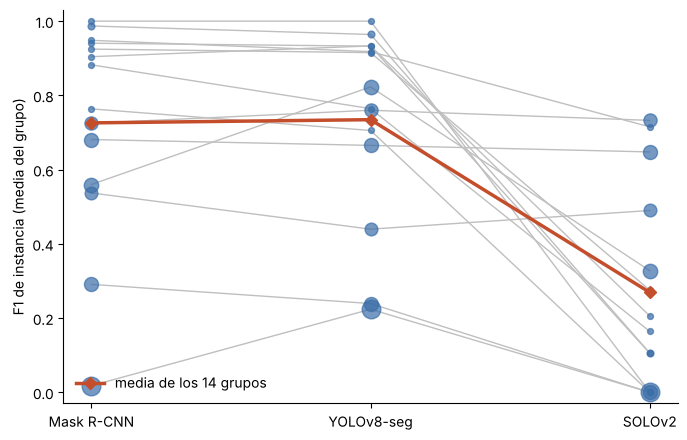

In [10]:
orden = ['maskrcnn', 'yolov8seg', 'solov2']
gg = res['por_grupo'][orden]
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(orden))
for grupo, fila in gg.iterrows():
    ax.plot(x, fila.values, color='0.75', lw=1, zorder=1)
    ax.scatter(x, fila.values, s=12 + 6 * n_img[grupo], color='#3b6ea8', alpha=0.7, zorder=2)
ax.plot(x, gg.mean().values, color='#c44e2b', lw=2.5, marker='D', label='media de los 14 grupos', zorder=3)
ax.set_xticks(x, [MODELOS[m] for m in orden])
ax.set_ylabel('F1 de instancia (media del grupo)')
ax.set_ylim(-0.03, 1.03)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.show()

**Tabla 5.4.** Contrastes por pares (unidad = grupo, n = 14; Wilcoxon pareado con corrección de Holm, IC95 bootstrap remuestreando grupos, MDE con potencia 0.80).

In [11]:
pares = res['pares'].copy()
for k, v in MODELOS.items():
    pares['par'] = pares['par'].str.replace(k, v)
display(pares.round(4))

,par,dif_media,de_dif,ic95_boot_grupos,wilcoxon_W,p,gana_a_en_grupos,p_holm,MDE,supera_delta
0,Mask R-CNN - SOLOv2,0.4567,0.3679,"(0.2683, 0.6393)",1.0,0.0002,13,0.0007,0.3556,True
1,Mask R-CNN - YOLOv8-seg,-0.0086,0.1052,"(-0.0655, 0.0389)",37.0,0.5525,9,0.5525,0.1017,False
2,SOLOv2 - YOLOv8-seg,-0.4653,0.3491,"(-0.6408, -0.2846)",3.0,0.0006,1,0.0012,0.3374,True


Con PQ como métrica secundaria:

In [12]:
res_pq = EI.analizar(CORR, metrica='pq')

== Resumen por modelo (test, sobre semillas)
            n_semillas  F1_img_media  F1_img_de  F1_grupo_media  PQ_img_media  PQ_img_de  PQ_grupo_media  PQ_grupo_de  AP_media   AP_de  AP50_media  F1_img_ic95  PQ_img_ic95  AP_ic95
modelo                                                                                                                                                                               
maskrcnn            5        0.4467     0.0173          0.7259        0.3133     0.0108          0.5250       0.0116    0.2168  0.0039      0.5871       0.0215       0.0134   0.0048
solov2              5        0.2967     0.0267          0.2692        0.2104     0.0170          0.1950       0.0162    0.1127  0.0053      0.2849       0.0332       0.0211   0.0066
yolov8seg           5        0.5208     0.0613          0.7345        0.3652     0.0398          0.5138       0.0194    0.2344  0.0082      0.6373       0.0761       0.0494   0.0101 

== pq por grupo (n = 14 grupos)
 modelo  m

**Lectura.**
- **SOLOv2 queda por debajo de los otros dos** con una diferencia grande (≈0.46 en F1 por grupo), muy por encima de δ = 0.03 y significativa tras Holm. Pierde en 13 de los 14 grupos frente a cada uno de los otros modelos. La tabla 5.4 muestra de dónde viene: su precisión es similar a la de los otros (0.59 frente a 0.60–0.63), pero su recall es la mitad (0.31 frente a 0.58–0.63). Deja de detectar la mitad de los tornillos. Una explicación plausible, no verificada con un experimento, es su forma de asignar objetos: SOLOv2 decide la presencia de una instancia en una cuadrícula de 40 × 40 celdas, que a 1280 px son celdas de unos 32 px, mientras que el tornillo mediano mide 12 px.
- **Mask R-CNN y YOLOv8-seg no se distinguen con estos datos.** La diferencia por grupo es de −0.009 (IC95 [−0.066, 0.039]; p de Holm = 0.55). El efecto mínimo detectable con 14 grupos es de 0.102, mayor que δ = 0.03, así que el resultado es **no concluyente**: no se puede afirmar que sean equivalentes, solo que la prueba no tiene potencia para separarlos.
- **La media por imagen y la media por grupo cuentan historias distintas.** Por imagen, YOLOv8-seg supera a Mask R-CNN (0.52 frente a 0.45), pero buena parte de esa ventaja viene del grupo 9, que tiene 28 de las 108 imágenes de prueba: allí Mask R-CNN casi no acierta (F1 0.02) y YOLOv8-seg llega a 0.22. Al usar el grupo como unidad, ese grupo pesa lo mismo que los demás y la ventaja desaparece. Por eso la conclusión se apoya en el análisis por grupo.
- **El reparto entre máquinas no cambia el patrón.** Las semillas de la RTX 3050 (45 y 46) quedan en el mismo rango que las de la RTX 3060 en F1 por imagen: Mask R-CNN 0.450 y 0.461 frente a 0.418–0.458; YOLOv8-seg 0.568 y 0.504 frente a 0.429–0.584; SOLOv2 0.305 y 0.287 frente a 0.256–0.326. Lo que cambia es el tiempo de cómputo.

### 5.4 Limitaciones

- **Pocos grupos en prueba.** Hay 14, y 8 de ellos tienen una o dos imágenes (7 con una sola). Eso limita la potencia: con Wilcoxon exacto y 14 pares, el p más pequeño posible es del orden de 10⁻⁴, pero detectar diferencias moderadas exige que un modelo gane en casi todos los grupos.
- **Marcos distintos.** SOLOv2 corre en MMDetection, con torch 2.1.2, porque mmcv 2.1 solo tiene versiones precompiladas para Windows con torch 2.1. Mask R-CNN y YOLOv8-seg usan torch 2.11. La evaluación es idéntica para los tres (el mismo código de métricas sobre las predicciones exportadas en formato COCO), pero las rutinas de entrenamiento no son idénticas.
- **Hiperparámetros por defecto.** Cada modelo usa la receta de su implementación de referencia, solo ajustada al tamaño de los tornillos (anclas, resolución). No hubo búsqueda de hiperparámetros, así que la comparación es entre recetas estándar, no entre el máximo alcanzable por cada arquitectura.
- **Presupuesto fijo de épocas.** 12/40/12 épocas por limitaciones de tiempo y GPU (6 GB). Un modelo que converja más lento queda en desventaja.
- **No determinismo de GPU.** Con la misma semilla, cuDNN no garantiza resultados idénticos. La variación entre semillas incluye ese ruido.